# Hypothesis testing: electric-bike use by rider type

**H1.** Do member and casual rides differ in electric-bike use once we compare them at the same station on the same day?

**H2.** Is that member–casual gap different on weekdays and weekends?

**Data.** Rides that started from January 1 through July 31, 2025, the same window as the EDA. Aggregated daily counts come from `scripts/export_daily_counts.py`, which reads the cleaned trip table. Later months are kept for forecast validation and testing, so these tests do not touch them.

**Run order.** Run `scripts/prepare_2025.py`, `scripts/clean_2025.py` and `scripts/export_daily_counts.py` first, or place the two exported files in `DATA_DIR`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Folder containing daily_rider_counts.csv and daily_station_rider_counts.parquet.
# In Colab, change this to the folder where you uploaded the two files.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts/clean_2025.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook inside the cloned project.")
DATA_DIR = ROOT / "data/clean"
OUT = ROOT / "results/hypothesis"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 5450

## 1. Load the data and check it against the EDA

`daily_rider_counts.csv` has one row per day and rider type. Its totals should reproduce EDA figure C.

In [2]:
daily = pd.read_csv(DATA_DIR / "daily_rider_counts.csv", parse_dates=["day"])
overall = daily.groupby("member_casual")[["rides", "electric"]].sum()
overall["share"] = overall.electric / overall.rides
print("Days per rider type:", daily.groupby("member_casual").size().to_dict())
overall

Days per rider type: {'casual': 212, 'member': 212}


,rides,electric,share
member_casual,,,
casual,4306502,3237467,0.751763
member,20815131,14408890,0.692232


In [3]:
raw_gap = overall.loc["casual", "share"] - overall.loc["member", "share"]
print(f"Unadjusted gap (casual - member): {raw_gap * 100:.2f} percentage points")

Unadjusted gap (casual - member): 5.95 percentage points


## 2. Build station × day strata

`daily_station_rider_counts.parquet` has one row per day, start station and rider type. Rides without a start station are excluded here (about 10,000 of 25.1 million).

Each **stratum** is one station on one day. Inside a stratum, both rider types face the same location, weather and roughly the same bike supply. A stratum can compare the two groups only if both rode there that day, so strata with a single rider type are dropped.

In [4]:
long = pd.read_parquet(DATA_DIR / "daily_station_rider_counts.parquet")
wide = long.pivot_table(index=["day", "start_station_id"], columns="member_casual",
                        values=["rides", "electric"], fill_value=0)
wide.columns = [f"{value}_{rider}" for value, rider in wide.columns]
wide = wide.reset_index()

strata = wide[(wide.rides_casual > 0) & (wide.rides_member > 0)].copy()
print(f"Station-days: {len(wide):,}; with both rider types: {len(strata):,}")
print(f"Casual rides kept: {strata.rides_casual.sum() / wide.rides_casual.sum():.1%}")
print(f"Member rides kept: {strata.rides_member.sum() / wide.rides_member.sum():.1%}")

Station-days: 453,377; with both rider types: 386,020
Casual rides kept: 99.9%
Member rides kept: 98.0%


## H1. Member vs. casual electric-bike share

- **H0:** within the same station and day, members and casual riders use electric bikes at the same rate.
- **H1:** the rates differ (two-sided).
- **Test statistic:** the stratified gap, a weighted average of the within-stratum differences in electric-bike share.

**Weights.** Each stratum gets the Mantel–Haenszel weight $n_C n_M / (n_C + n_M)$. It is small whenever either group is small, because a share computed from one or two rides is unreliable.

In [5]:
nC = strata.rides_casual.to_numpy(np.int64)
nM = strata.rides_member.to_numpy(np.int64)
eC = strata.electric_casual.to_numpy(np.int64)
eM = strata.electric_member.to_numpy(np.int64)
n, e = nC + nM, eC + eM
wt = nC * nM / n

def stratified_gap(casual_electric):
    """Weighted mean of casual minus member electric share across strata."""
    diff = casual_electric / nC - (e - casual_electric) / nM
    return np.sum(wt * diff) / wt.sum()

h1_observed = stratified_gap(eC)
print(f"Unadjusted gap:          {raw_gap * 100:.2f} pp")
print(f"Station-day adjusted gap: {h1_observed * 100:.2f} pp")

Unadjusted gap:          5.95 pp
Station-day adjusted gap: 5.89 pp


Controlling for station and day barely changes the gap. Casual riders choose electric bikes more often even at the same station on the same day, so where and when they ride does not explain the difference.

### Stratified permutation test

If H0 holds, the member/casual label carries no information about bike type within a stratum. We therefore reassign labels at random inside each stratum while keeping its ride count, electric-bike count and number of casual rides fixed. Drawing the casual riders' electric-bike count from a hypergeometric distribution does exactly this without shuffling 25 million rows.

In [6]:
rng = np.random.default_rng(SEED)
N_PERM = 1_000
h1_null = np.array([stratified_gap(rng.hypergeometric(e, n - e, nC)) for _ in range(N_PERM)])
h1_p = (1 + np.sum(np.abs(h1_null) >= abs(h1_observed))) / (N_PERM + 1)

print(f"Largest |gap| under H0: {np.abs(h1_null).max() * 100:.3f} pp")
print(f"Two-sided p-value: {h1_p:.4f}  (the smallest possible with {N_PERM:,} permutations)")

Largest |gap| under H0: 0.089 pp
Two-sided p-value: 0.0010  (the smallest possible with 1,000 permutations)


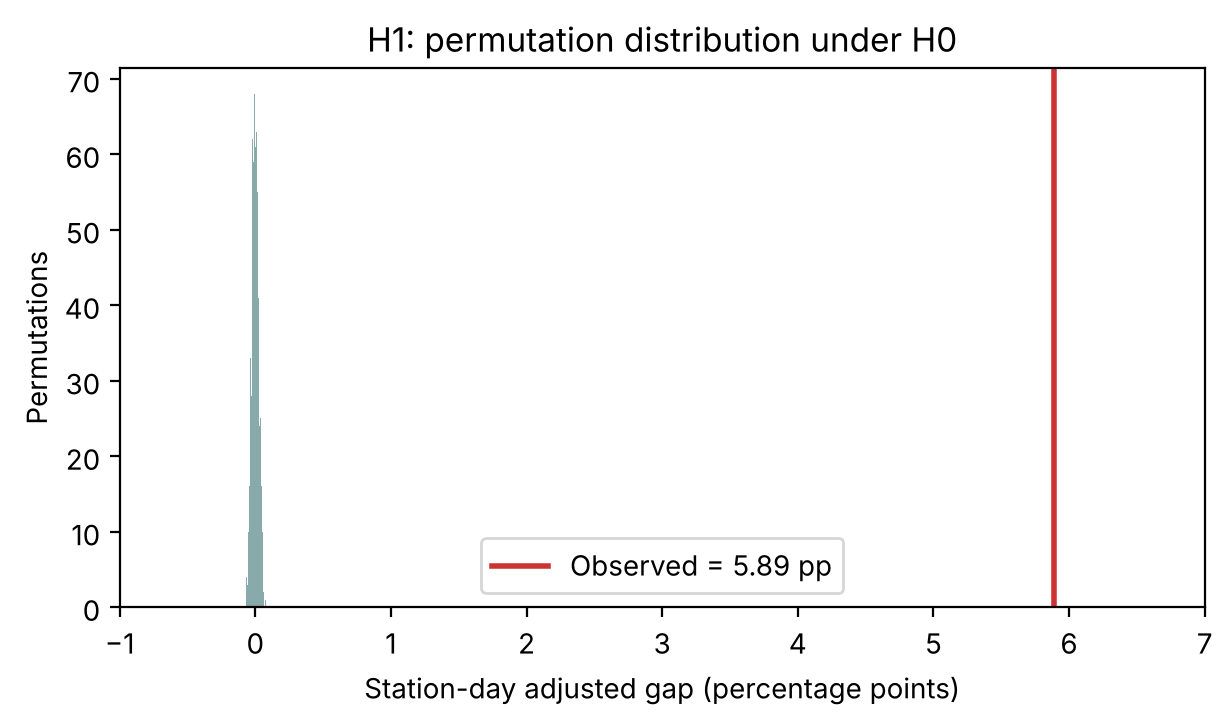

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(h1_null * 100, bins=40, color="#8aa")
ax.axvline(h1_observed * 100, color="#c33", lw=2, label=f"Observed = {h1_observed * 100:.2f} pp")
ax.set_xlim(-1, 7)
ax.set(xlabel="Station-day adjusted gap (percentage points)", ylabel="Permutations",
       title="H1: permutation distribution under H0")
ax.legend()
fig.savefig(OUT / "H1_permutation.png", dpi=180, bbox_inches="tight")
plt.show()

**Caveat.** The permutation test treats rides within a stratum as exchangeable. Rides are not fully independent: one person may ride several times a day and groups ride together. That makes the null distribution too narrow and the p-value too small. The next step addresses this.

### 95% confidence interval: day-level bootstrap

Rides on the same day share weather, visitors and repeat riders. Resampling whole days, rather than rides, keeps that dependence intact. Each bootstrap sample draws 212 days with replacement and recomputes the stratified gap.

In [8]:
strata["wd"] = wt * (eC / nC - eM / nM)
strata["wt"] = wt
by_day = strata.groupby("day")[["wd", "wt"]].sum()

idx = rng.integers(0, len(by_day), size=(2_000, len(by_day)))
h1_boot = by_day.wd.to_numpy()[idx].sum(axis=1) / by_day.wt.to_numpy()[idx].sum(axis=1)
h1_ci = np.percentile(h1_boot, [2.5, 97.5])

print(f"Adjusted gap: {h1_observed * 100:.2f} pp, 95% CI [{h1_ci[0] * 100:.2f}, {h1_ci[1] * 100:.2f}]")
print(f"Bootstrap SE / permutation SD: {h1_boot.std() / h1_null.std():.1f}x")

Adjusted gap: 5.89 pp, 95% CI [5.44, 6.34]
Bootstrap SE / permutation SD: 9.0x


In [9]:
daily_gap = by_day.wd / by_day.wt
print(f"Daily adjusted gap: median {daily_gap.median() * 100:.2f} pp, "
      f"days with gap <= 0: {(daily_gap <= 0).sum()} of {len(daily_gap)}")

Daily adjusted gap: median 6.89 pp, days with gap <= 0: 1 of 212


**H1 conclusion.** Casual rides use electric bikes about 6 percentage points more often than member rides, and the gap remains when both groups are compared at the same station on the same day. Allowing for dependence within days widens the uncertainty several times over, yet the interval stays far from zero and the gap appears on almost every day.

The data cannot explain *why*. In 2025 members paid a lower per-minute e-bike fee than non-members ($0.25 vs. $0.38 in NYC), yet casual riders still chose e-bikes more often, so the fee difference alone does not explain the gap. Trip purpose, familiarity with the system and e-bike availability at the moment of rental remain possible explanations. The trip records contain no inventory or fare data to separate them.

## H2. Weekday vs. weekend gap

On weekdays many members commute while casual riders mostly ride for leisure. On weekends both groups ride mostly for leisure. If trip purpose drives part of the H1 gap, the gap should be smaller on weekends.

- **Daily gap:** the station-adjusted casual − member gap for each day, computed as in H1.
- **H0:** the mean daily gap is the same on weekdays and weekends.
- **H1:** the means differ (two-sided).
- **Test statistic:** mean weekday gap − mean weekend gap. Each day counts equally.
- **Permutation:** weekday/weekend labels are shuffled only among days of the same month, so seasonal changes cannot drive the result.

In [10]:
h2 = daily_gap.rename("gap").reset_index()
h2["day"] = pd.to_datetime(h2.day)
h2["month"] = h2.day.dt.month
h2["weekend"] = h2.day.dt.dayofweek >= 5
federal_holidays = pd.to_datetime(["2025-01-01", "2025-01-20", "2025-02-17",
                                   "2025-05-26", "2025-06-19", "2025-07-04"])
h2["holiday"] = h2.day.isin(federal_holidays)

def weekday_minus_weekend(gap, weekend):
    return gap[~weekend].mean() - gap[weekend].mean()

def h2_test(data, n_perm=10_000, n_boot=2_000, seed=SEED):
    rng = np.random.default_rng(seed)
    gap, weekend, month = data.gap.to_numpy(), data.weekend.to_numpy(), data.month.to_numpy()
    observed = weekday_minus_weekend(gap, weekend)

    months = [np.flatnonzero(month == m) for m in np.unique(month)]
    null = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = weekend.copy()
        for rows in months:
            shuffled[rows] = rng.permutation(weekend[rows])
        null[i] = weekday_minus_weekend(gap, shuffled)
    p = (1 + np.sum(np.abs(null) >= abs(observed))) / (n_perm + 1)

    # Bootstrap within each month x day-type cell to keep the design fixed.
    cells = [np.flatnonzero((month == m) & (weekend == w)) for m in np.unique(month) for w in (False, True)]
    boot = np.empty(n_boot)
    for i in range(n_boot):
        rows = np.concatenate([rng.choice(c, len(c)) for c in cells])
        boot[i] = weekday_minus_weekend(gap[rows], weekend[rows])
    return observed, null, p, np.percentile(boot, [2.5, 97.5])

h2_observed, h2_null, h2_p, h2_ci = h2_test(h2)
print(f"Weekday mean gap: {h2.gap[~h2.weekend].mean() * 100:.2f} pp ({(~h2.weekend).sum()} days)")
print(f"Weekend mean gap: {h2.gap[h2.weekend].mean() * 100:.2f} pp ({h2.weekend.sum()} days)")
print(f"Difference: {h2_observed * 100:.2f} pp, 95% CI [{h2_ci[0] * 100:.2f}, {h2_ci[1] * 100:.2f}], p = {h2_p:.4f}")

Weekday mean gap: 8.45 pp (152 days)
Weekend mean gap: 5.03 pp (60 days)
Difference: 3.42 pp, 95% CI [2.82, 4.07], p = 0.0001


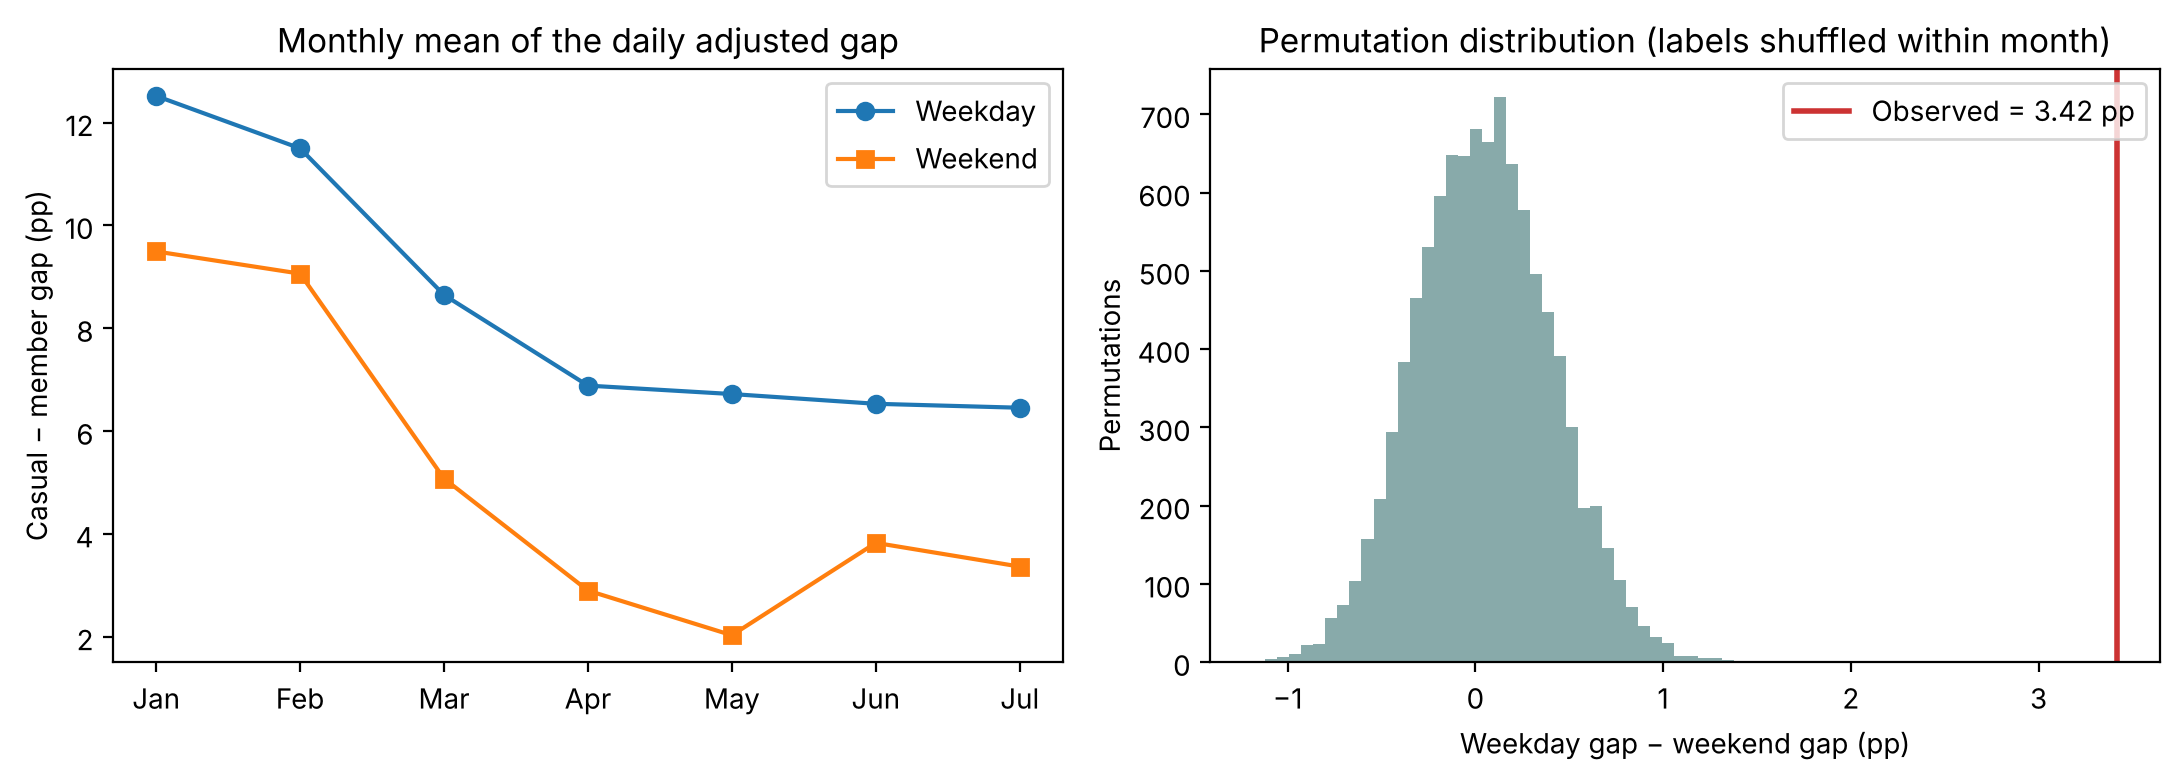

weekend,False,True
month,,
1,12.52,9.49
2,11.50,9.06
3,8.65,5.08
4,6.88,2.90
5,6.72,2.03
6,6.53,3.83
7,6.45,3.36


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
monthly = h2.groupby(["month", "weekend"]).gap.mean().unstack() * 100
axes[0].plot(monthly.index, monthly[False], "o-", label="Weekday")
axes[0].plot(monthly.index, monthly[True], "s-", label="Weekend")
axes[0].set_xticks(range(1, 8), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"])
axes[0].set(ylabel="Casual − member gap (pp)", title="Monthly mean of the daily adjusted gap")
axes[0].legend()

axes[1].hist(h2_null * 100, bins=40, color="#8aa")
axes[1].axvline(h2_observed * 100, color="#c33", lw=2, label=f"Observed = {h2_observed * 100:.2f} pp")
axes[1].set(xlabel="Weekday gap − weekend gap (pp)", ylabel="Permutations",
            title="Permutation distribution (labels shuffled within month)")
axes[1].legend()
plt.tight_layout()
fig.savefig(OUT / "H2_weekday_weekend.png", dpi=180, bbox_inches="tight")
plt.show()
monthly.round(2)

### Robustness: exclude federal holidays

Holidays count as weekdays above, although riding on those days often resembles a weekend. Dropping the six federal holidays in the window checks whether they affect the result.

In [12]:
obs, _, p, ci = h2_test(h2[~h2.holiday])
print(f"Without holidays: difference {obs * 100:.2f} pp, 95% CI [{ci[0] * 100:.2f}, {ci[1] * 100:.2f}], p = {p:.4f}")

Without holidays: difference 3.49 pp, 95% CI [2.92, 4.08], p = 0.0001


**H2 conclusion.** The gap is about 40% smaller on weekends than on weekdays, in every month and with or without holidays. It does not disappear on weekends. The pattern fits trip purpose explaining part of the gap, with a remaining difference between the two rider groups. Weekdays and weekends also differ in station use and bike availability, so this is an association, not a causal estimate.

**Why the H1 and H2 numbers differ.** H1 pools rides, so busy days weigh more. H2 gives every day equal weight. Busy summer days have smaller gaps, which pulls the pooled H1 estimate below the average of the daily gaps.

## Summary

| | Estimate | 95% CI | p-value |
|---|---:|---:|---:|
| H1: casual − member electric share, unadjusted | 5.95 pp | | |
| H1: same, adjusted for station × day | 5.89 pp | 5.44 to 6.34 | < 0.001 |
| H2: weekday gap − weekend gap | 3.42 pp | 2.82 to 4.07 | < 0.001 |
| H2 without federal holidays | 3.49 pp | 2.92 to 4.08 | < 0.001 |

*Interval endpoints come from bootstrap resampling with the fixed seed above.*

**Limitations**
- No station inventory: an electric bike may be unavailable when a rider arrives.
- No fare data in the trip records. Members pay a lower per-minute e-bike fee, which could affect bike choice.
- No rider IDs, so repeat riders make rides dependent. The day-level bootstrap accounts for dependence within days but not across days.
- January–July only. A full-year check will follow once the forecasting test period is no longer needed.
- Observational data: the results describe associations, not causes.

**Future work.** The adjusted gap falls from about 12 pp in January to about 6 pp in July. This pattern was not part of either hypothesis and needs its own test before drawing conclusions.